In [102]:
#IMPORTAÇÕES:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#CARREGAMENTO DOS DADOS:
df = pd.read_csv('melb_data.csv')

In [103]:
#1> DIAGNÓSTICO INICIAL:
print("Diagnostico inicial\n\n")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

diagnostico = pd.DataFrame({
    'Tipo de Dado': df.dtypes,
    'Valores Ausentes': df.isnull().sum()
})

diagnostico

Diagnostico inicial


Dimensões do dataset: 13580 linhas e 21 colunas


,Tipo de Dado,Valores Ausentes
Suburb,str,0
Address,str,0
Rooms,int64,0
Type,str,0
Price,float64,0
Method,str,0
SellerG,str,0
Date,str,0
Distance,float64,0
Postcode,float64,0


In [104]:
#2> RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
tabela_resumo = pd.DataFrame({
    'Valores Ausentes': df.isnull().sum(),
    'Porcentagem %': (df.isnull().mean() * 100).round(2)
})

tabela_resumo

,Valores Ausentes,Porcentagem %
Suburb,0,0.00
Address,0,0.00
Rooms,0,0.00
Type,0,0.00
Price,0,0.00
Method,0,0.00
SellerG,0,0.00
Date,0,0.00
Distance,0,0.00
Postcode,0,0.00


vejo que as colunas: 'Car', 'BuildingArea', 'YearBuilt', 'CouncilArea' tem elementos menores que 13580 (O total de cada coluna)


<Axes: >

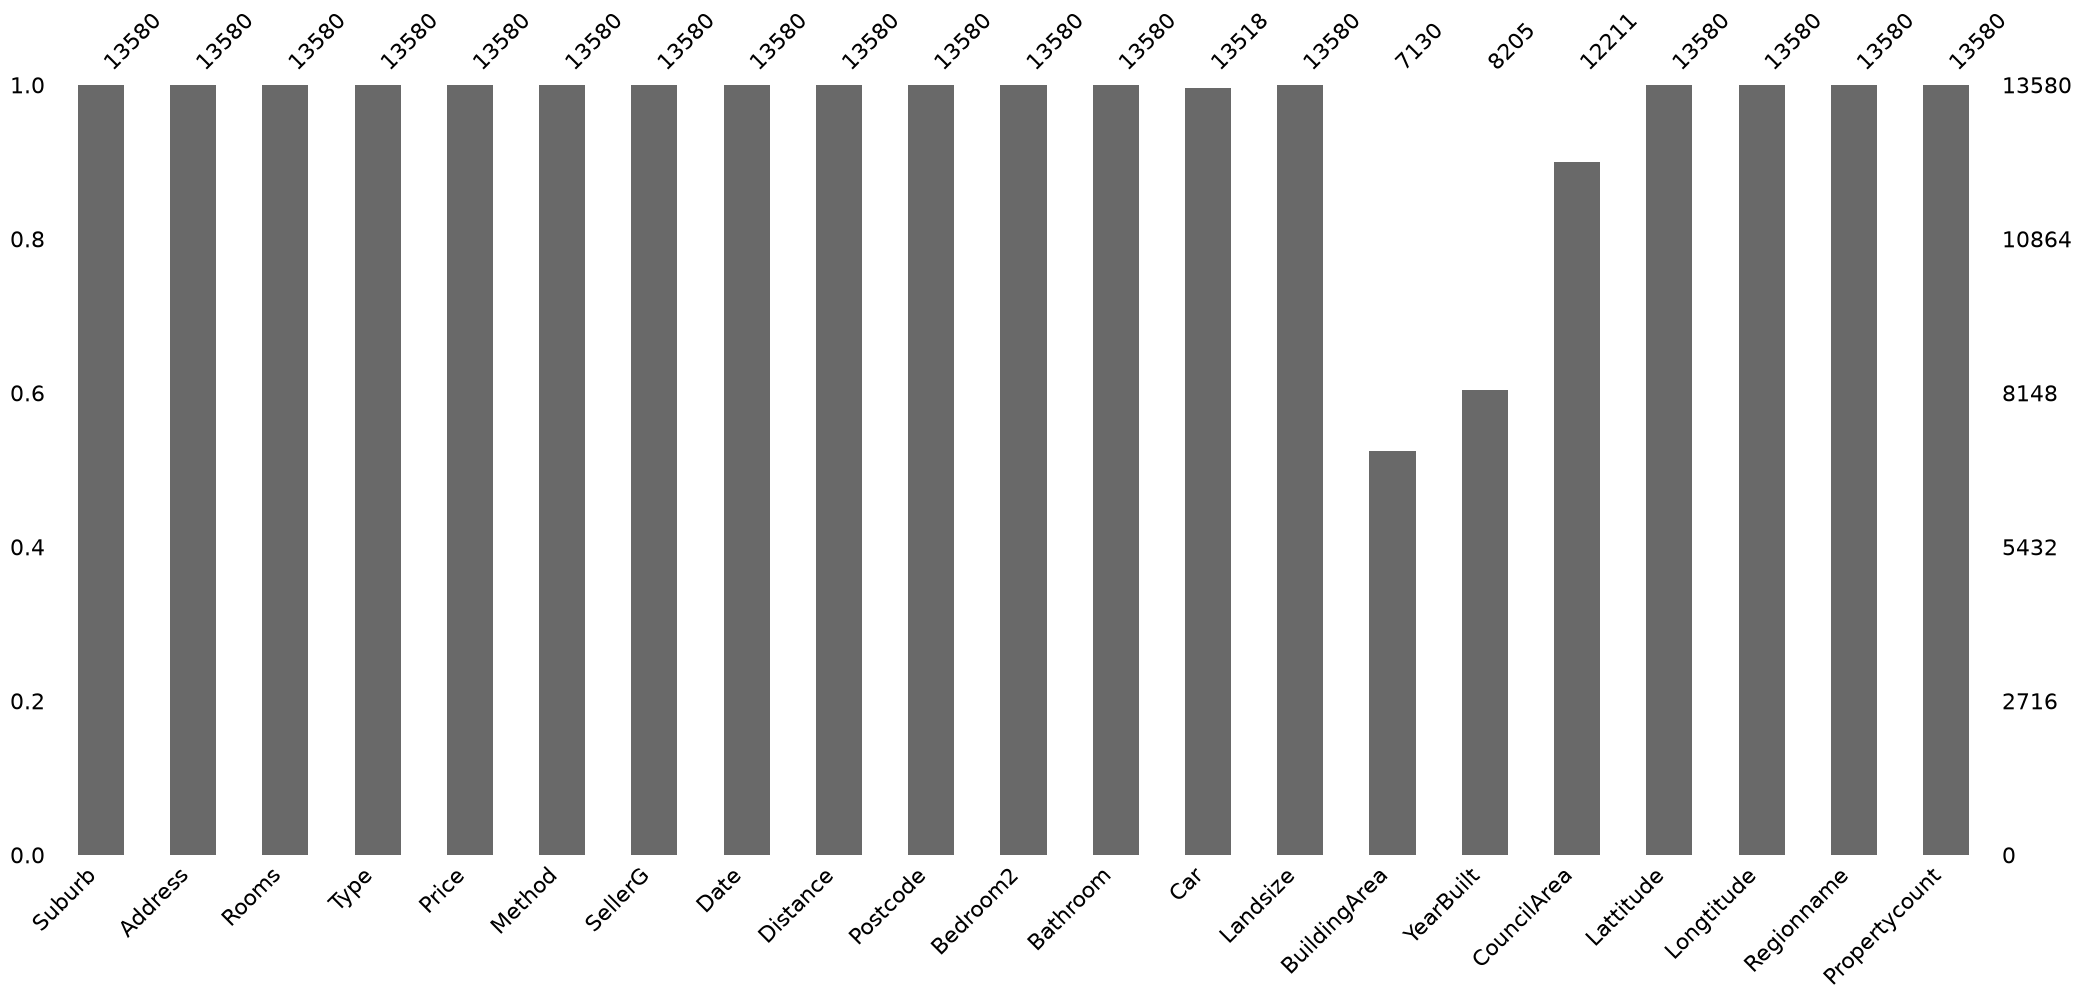

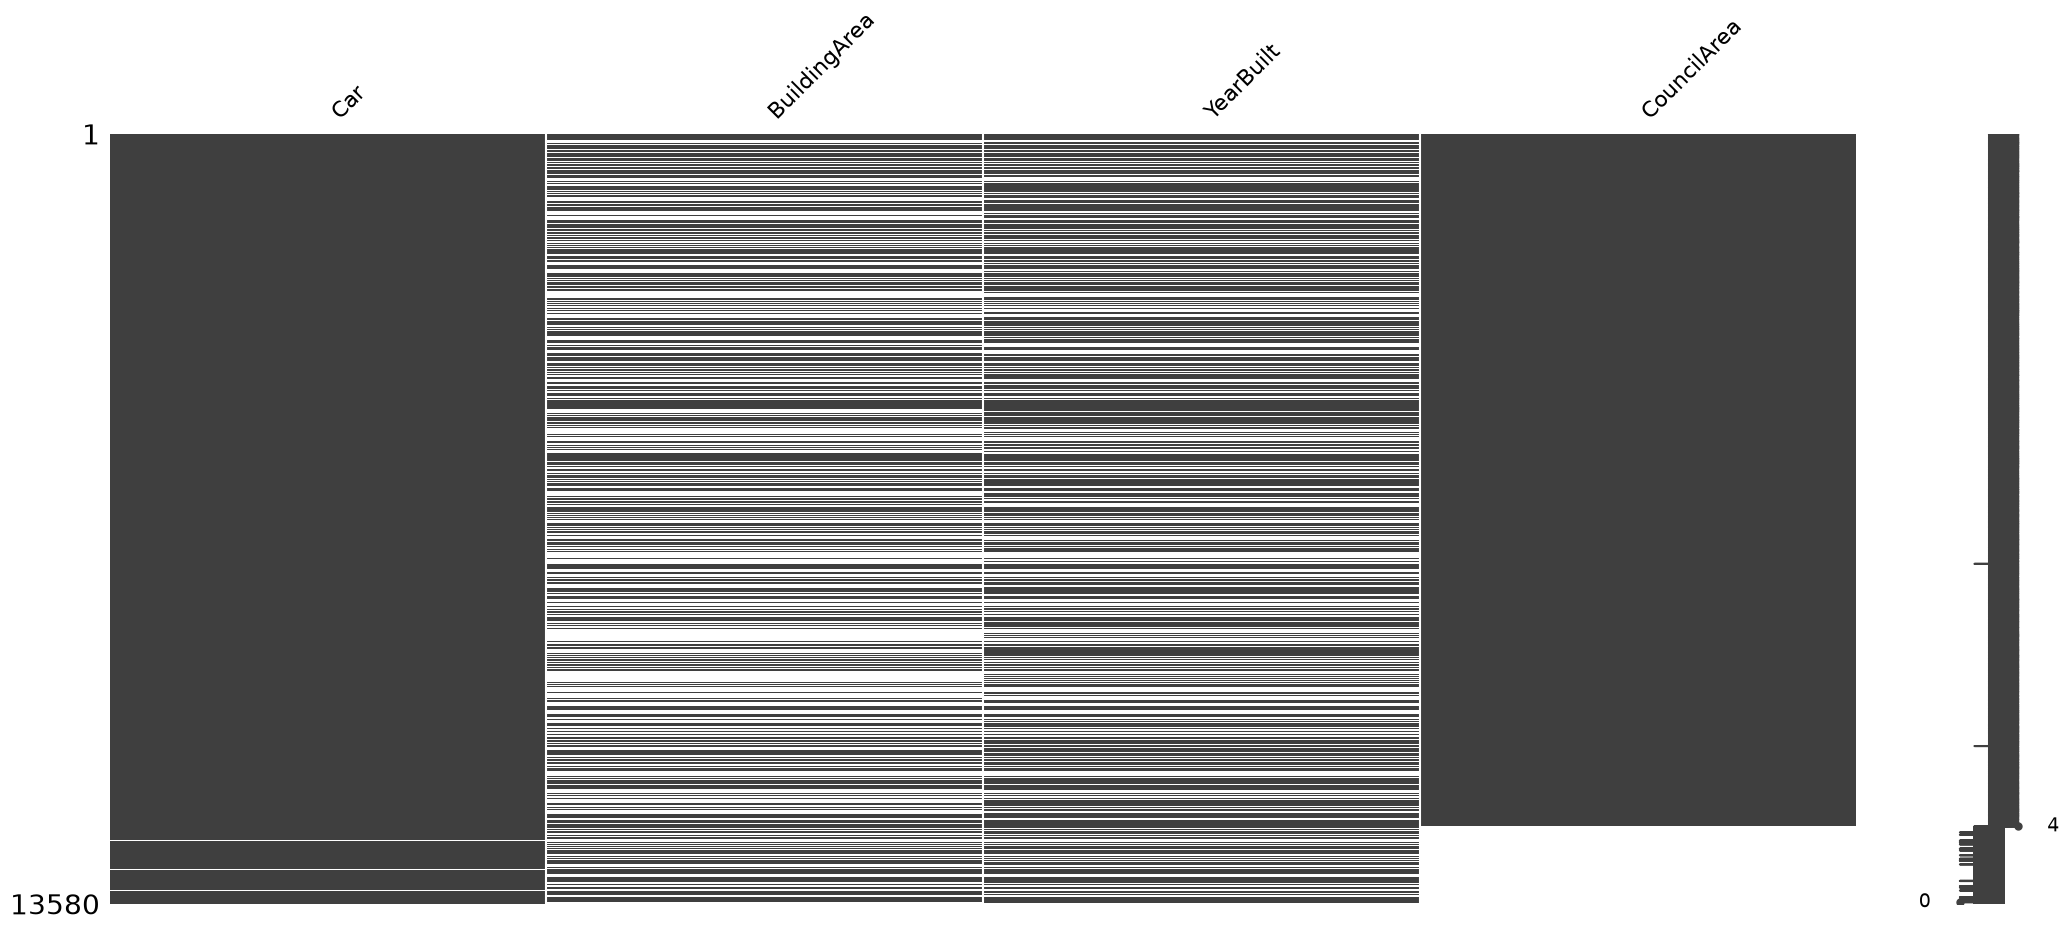

In [105]:
#3> VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA:
import missingno as msno

msno.bar(df)
print("vejo que as colunas: 'Car', 'BuildingArea', 'YearBuilt', 'CouncilArea' tem elementos menores que 13580 (O total de cada coluna)")
msno.matrix(df[['Car', 'BuildingArea', 'YearBuilt', 'CouncilArea']])

In [106]:
#4.1> ESTRATÉGIA 1 - REMOÇÃO
df_remocao = df.copy()

df_remocao = df_remocao.dropna(subset=['Car', 'BuildingArea', 'YearBuilt', 'CouncilArea'])

In [107]:
#4.2> ESTRATÉGIA 2 - IMPUTAÇÃO
df_imputacao = df.copy()

colunas_nulas = ['Car', 'BuildingArea', 'YearBuilt', 'CouncilArea']

for col in colunas_nulas:
    if df_imputacao[col].dtype in ['float64', 'int64']:
        valor_imputacao = df_imputacao[col].median()
        df_imputacao[col] = df_imputacao[col].fillna(valor_imputacao)
    else:
        valor_imputacao = df_imputacao[col].mode()[0]
        df_imputacao[col] = df_imputacao[col].fillna(valor_imputacao)


In [108]:
#5> COMPARAÇÃO ENTRE AS ESTRATÉGIAS:
print("Comparação entre as estratégias:\n")
print("Imputação aos nulos: ")
df_imputacao

Comparação entre as estratégias:

Imputação aos nulos: 


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,126.0,1970.0,Yarra,-37.79960,144.99840,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.80790,144.99340,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.80930,144.99440,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,126.0,1970.0,Yarra,-37.79690,144.99690,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.80720,144.99410,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13575,Wheelers Hill,12 Strada Cr,4,h,1245000.0,S,Barry,26/08/2017,16.7,3150.0,...,2.0,2.0,652.0,126.0,1981.0,Moreland,-37.90562,145.16761,South-Eastern Metropolitan,7392.0
13576,Williamstown,77 Merrett Dr,3,h,1031000.0,SP,Williams,26/08/2017,6.8,3016.0,...,2.0,2.0,333.0,133.0,1995.0,Moreland,-37.85927,144.87904,Western Metropolitan,6380.0
13577,Williamstown,83 Power St,3,h,1170000.0,S,Raine,26/08/2017,6.8,3016.0,...,2.0,4.0,436.0,126.0,1997.0,Moreland,-37.85274,144.88738,Western Metropolitan,6380.0
13578,Williamstown,96 Verdon St,4,h,2500000.0,PI,Sweeney,26/08/2017,6.8,3016.0,...,1.0,5.0,866.0,157.0,1920.0,Moreland,-37.85908,144.89299,Western Metropolitan,6380.0


In [109]:
print("Remoção dos nulos: ")
df_remocao

Remoção dos nulos: 


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.00,1900.0,Yarra,-37.80790,144.99340,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.00,1900.0,Yarra,-37.80930,144.99440,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.00,2014.0,Yarra,-37.80720,144.99410,Northern Metropolitan,4019.0
6,Abbotsford,124 Yarra St,3,h,1876000.0,S,Nelson,7/05/2016,2.5,3067.0,...,2.0,0.0,245.0,210.00,1910.0,Yarra,-37.80240,144.99930,Northern Metropolitan,4019.0
7,Abbotsford,98 Charles St,2,h,1636000.0,S,Nelson,8/10/2016,2.5,3067.0,...,1.0,2.0,256.0,107.00,1890.0,Yarra,-37.80600,144.99540,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12205,Whittlesea,30 Sherwin St,3,h,601000.0,S,Ray,29/07/2017,35.5,3757.0,...,2.0,1.0,972.0,149.00,1996.0,Whittlesea,-37.51232,145.13282,Northern Victoria,2170.0
12206,Williamstown,75 Cecil St,3,h,1050000.0,VB,Williams,29/07/2017,6.8,3016.0,...,1.0,0.0,179.0,115.00,1890.0,Hobsons Bay,-37.86558,144.90474,Western Metropolitan,6380.0
12207,Williamstown,2/29 Dover Rd,1,u,385000.0,SP,Williams,29/07/2017,6.8,3016.0,...,1.0,1.0,0.0,35.64,1967.0,Hobsons Bay,-37.85588,144.89936,Western Metropolitan,6380.0
12209,Windsor,201/152 Peel St,2,u,560000.0,PI,hockingstuart,29/07/2017,4.6,3181.0,...,1.0,1.0,0.0,61.60,2012.0,Stonnington,-37.85581,144.99025,Southern Metropolitan,4380.0


In [110]:
#RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO:
"""Depende das regras de negocio que a organização leve, se em acaso de dados faltantes deixar e subistituir por
'Desconhecido' ou algo do tipo ou Remover a linha completamente por ter um dado importante nulo.
Eu pessoalmente neste caso eu escolheria remover-los, apesar de ter outras informações importantes na mesma linha 
que não são nulas, ainda sim não adianta guardar um dado que não tem quase nada de util."""
""""""

''

In [111]:
df_imputacao[['Price', 'Landsize']].mean()
df_imputacao[['Price', 'Landsize']].median()
"""Não, a média dá um valor enorme por algum motivo, é melhor a mediana mesmo"""

'Não, a média dá um valor enorme por algum motivo, é melhor a mediana mesmo'